In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Library

In [8]:
# 데이터 전처리
import pandas as pd
import numpy as np
import gzip
import json
import copy

# 작업 진행률 시각화
from tqdm import tqdm
tqdm.pandas()


# 시각화
import matplotlib.pyplot as plt
import seaborn as sns

# Torch 모델 구조
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# BERT Model
# Fine Tuning
from transformers import AutoModel, AutoTokenizer
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback
from transformers.modeling_outputs import SequenceClassifierOutput


# sklearn 전처리, 데이터 분할, 성능 평가지표
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Utils

In [3]:
# 데이터 불러오기
def parse(path):
  g = gzip.open(path, 'rb')
  for l in g:
    yield json.loads(l)

def getDF(path):
  i = 0
  df = {}
  for d in parse(path):
    df[i] = d
    i += 1
  return pd.DataFrame.from_dict(df, orient='index')

# Load Data

## Original

In [4]:
# 리뷰 데이터셋 확인
cell_phone = getDF('/content/drive/MyDrive/Dataset/Amazon_Dataset/Review/Cell_Phones_and_Accessories.jsonl.gz')

print(cell_phone.shape)
cell_phone.head()

(20812945, 10)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,4.0,No white background! It’s clear!,I bought this bc I thought it had the nice whi...,[{'small_image_url': 'https://images-na.ssl-im...,B08L6L3X1S,B08L6L3X1S,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1612044451196,0,True
1,5.0,Awesome! Great price! Works well!,Perfect. How pissed am I that I recently paid ...,[],B079BPGF6C,B079BPGF6C,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1534443517349,2,True
2,5.0,Worked but took an hour to install,Overall very happy with the end result. If you...,[{'small_image_url': 'https://m.media-amazon.c...,B088DR7Z5B,B0BBGGC8F2,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1629235304798,3,True
3,4.0,Decent,Lasted about 9 months then the lock button bro...,[{'small_image_url': 'https://images-na.ssl-im...,B07XRDHDNQ,B07XRDHDNQ,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1590470082910,0,True
4,5.0,LOVE IT!,LOVE THIS CASE! Works better than my expensive...,[],B00A8ZDL9Y,B00A8ZDL9Y,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1408994588000,0,True


In [5]:
# 리뷰 데이터셋 확인
clothing_shoes = getDF('/content/drive/MyDrive/Dataset/Amazon_Dataset/Review/Clothing_Shoes_and_Jewelry.jsonl.gz')

print(clothing_shoes.shape)
clothing_shoes.head()

(66033346, 10)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,3.0,Arrived Damaged : liquid in hub locker!,"Unfortunately Amazon in their wisdom (cough, c...",[{'small_image_url': 'https://m.media-amazon.c...,B096S6LZV4,B09NSZ5QMF,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1677938767351,0,True
1,3.0,Useless under 40 degrees.,Useless under 40 degrees unless you’re just ru...,[],B09KMDBDCN,B08NGL3X17,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1677083819242,0,False
2,4.0,"Not waterproof, but a very comfy shoe.",I purchased these bc they are supposed to be w...,[],B096N5WK8Q,B07RGM3DYC,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1675524098918,11,True
3,4.0,"Lovely, but QA issues with sewing",I’ll start by saying I love this robe! I trul...,[{'small_image_url': 'https://images-na.ssl-im...,B07JR4QBZ4,B07BWS4CSM,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1545114577507,26,True
4,2.0,Just ok,Don't be fooled by the description. I was free...,[],B09GY958RK,B09GY6SG2C,AGGZ357AO26RQZVRLGU4D4N52DZQ,1645223372746,1,True


In [8]:
# 아이템 메타 데이터셋 확인
meta_cell_phone = getDF('/content/drive/MyDrive/Dataset/Amazon_Dataset/Meta/meta_Cell_Phones_and_Accessories.jsonl.gz')

print(meta_cell_phone.shape)
meta_cell_phone.head()

(1288490, 16)


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together,subtitle,author
0,Cell Phones & Accessories,ARAREE Slim Diary Cell Phone Case for Samsung ...,3.8,5,"[Genuine Cow leather with 6 different colors, ...","[JUST LOOK, You can tell the difference. Make ...",None,[{'thumb': 'https://m.media-amazon.com/images/...,[],araree,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Product Dimensions': '3.35 x 0.59 x 6.18 inc...,B013SK1JTY,None,NaN,NaN
1,Cell Phones & Accessories,Bastmei for OnePlus 7T Case Extremely Light Ul...,4.4,177,[Ultra-thin & Ultra-light: The ultra slim fit ...,[],11.98,[{'thumb': 'https://m.media-amazon.com/images/...,[],Bastmei,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Package Dimensions': '7.6 x 4.29 x 0.75 inch...,B07ZPSG8P5,None,NaN,NaN
2,Cell Phones & Accessories,Wireless Fones Branded New Iphone 5C/LITE Hot ...,4.0,2,[],[],None,[{'thumb': 'https://m.media-amazon.com/images/...,[],WIRELESS FONES,"[Cell Phones & Accessories, iPhone Accessories]","{'Item model number': 'Apple Iphone 5C', 'Othe...",B00GKR3L12,None,NaN,NaN
3,Cell Phones & Accessories,"iPhone 6 Plus + Case, DandyCase Perfect PATTER...",4.0,15,"[Slim-Fit design for the iPhone 6 Plus (5.5"" s...",[Case does not need to be removed for charging...,None,[{'thumb': 'https://m.media-amazon.com/images/...,[],DandyCase,"[Cell Phones & Accessories, iPhone Accessories]",{'Product Dimensions': '5.43 x 0.28 x 2.64 inc...,B00PB8U8BW,None,NaN,NaN
4,Cell Phones & Accessories,"Case for Galaxy S6/S6 Edge, Thin Translucent V...",4.0,1,[],[],None,[{'thumb': 'https://m.media-amazon.com/images/...,[],7Pite,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Package Dimensions': '8.31 x 3.74 x 0.55 inc...,B07D3RHSRV,None,NaN,NaN


In [ ]:
# 아이템 메타 데이터셋 확인
meta_clothing_shoes = getDF('/content/drive/MyDrive/Dataset/Amazon_Dataset/Meta/meta_Clothing_Shoes_and_Jewelry.jsonl.gz')

print(meta_clothing_shoes.shape)
meta_clothing_shoes.head()

In [ ]:
# 공통으로 존재하는 parent_asin Column으로 결합.
cell_phone = cell_phone.merge(meta_cell_phone, on='parent_asin', how='left')

print(cell_phone.shape)
cell_phone.head()

In [ ]:
# 공통으로 존재하는 parent_asin Column으로 결합.
clothing_shoes = clothing_shoes.merge(meta_clothing_shoes, on='parent_asin', how='left')

print(clothing_shoes.shape)
clothing_shoes.head()

## Filtered

In [16]:
clothing_shoes_img = pd.read_pickle('/content/drive/MyDrive/Dataset/Amazon_Dataset/Preprocessed/Amazon_Clothing_Shoes_and_Jewerly_Img_Filtered_Top3.pkl')
print(clothing_shoes_img.shape)
clothing_shoes_img.head()

(67248, 27)


,rating,title_x,text,images_x,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,...,images_y,videos,store,categories,details,bought_together,subtitle,author,year,month
0,4.0,Pretty bit could be lighter steel color,Pretty colored earrings but color of stainless...,[{'small_image_url': 'https://images-na.ssl-im...,B08HQPWVCC,B08HQPWVCC,AFJBKPK5W56XWSNPQU2WW66ISWYQ,1618793053135,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[],Udalyn,"[Clothing, Shoes & Jewelry, Women, Jewelry, Ea...",{'Package Dimensions': '3.58 x 2.52 x 0.98 inc...,None,NaN,NaN,2021,4
1,5.0,Nice earrings.,Great little earrings. Perfect size. Not too b...,[{'small_image_url': 'https://images-na.ssl-im...,B08JQ88186,B08JQ88186,AFJBKPK5W56XWSNPQU2WW66ISWYQ,1605135397523,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[],ZENI,"[Clothing, Shoes & Jewelry, Women, Jewelry, Ea...",{'Package Dimensions': '5.59 x 3.98 x 0.71 inc...,None,NaN,NaN,2020,11
2,5.0,Works great,Great bracelet key chain. Perfect for busy mom...,[{'small_image_url': 'https://images-na.ssl-im...,B07YXXR1DG,B07YXXR1DG,AFJBKPK5W56XWSNPQU2WW66ISWYQ,1573790298428,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[],Konikit,"[Clothing, Shoes & Jewelry, Women, Accessories...",{'Package Dimensions': '6 x 4.2 x 0.5 inches; ...,None,NaN,NaN,2019,11
3,4.0,Looks just like picture,This is a nice patriotic tank. The medium fits...,[{'small_image_url': 'https://images-na.ssl-im...,B07RHSJQQN,B07RHSJQQN,AFJBKPK5W56XWSNPQU2WW66ISWYQ,1559769387979,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[],YEXIPO,"[Clothing, Shoes & Jewelry, Novelty & More, Cl...",{'Product Dimensions': '4 x 3 x 1 inches; 6 Ou...,None,NaN,NaN,2019,6
4,5.0,Nice comfortable shirt,Great boys shirt. My grandson wears a medium i...,[{'small_image_url': 'https://images-na.ssl-im...,B07LFZRYC2,B07LFZRYC2,AFJBKPK5W56XWSNPQU2WW66ISWYQ,1558729138171,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[],Hurley,"[Clothing, Shoes & Jewelry, Boys, Clothing, To...",{'Package Dimensions': '8.54 x 6.65 x 3.78 inc...,None,NaN,NaN,2019,5


In [17]:
cell_phone_img = pd.read_pickle('/content/drive/MyDrive/Dataset/Amazon_Dataset/Preprocessed/Cell_Phones_and_Accessories_Img_Filtered_Top3.pkl')
print(cell_phone_img.shape)
cell_phone_img.head()

(23801, 27)


,rating,title_x,text,images_x,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,...,images_y,videos,store,categories,details,bought_together,subtitle,author,year,month
0,3.0,One shield came scratched; decent privacy though,"Nice privacy shield. Good color, fits well, et...",[{'small_image_url': 'https://m.media-amazon.c...,B0BJKYJR3L,B0BJKYJR3L,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,1674085233816,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Best Screen Protector EVER - For i...,Jephuwneh,"[Cell Phones & Accessories, Accessories, Maint...","{'Product Dimensions': '6.18""L x 2.91""W', 'Ite...",None,NaN,NaN,2023,1
1,5.0,Awesome! Wireless Apple Watch charging is so u...,"This thing is great. It's not too big, has a d...",[{'small_image_url': 'https://m.media-amazon.c...,B0BHTZQHQW,B0BHTZQHQW,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,1669592529793,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[],NEOCOR,"[Cell Phones & Accessories, Accessories, Charg...",{'Product Dimensions': '4.1 x 2.6 x 0.84 inche...,None,NaN,NaN,2022,11
2,5.0,Sturdy Phone Holder! Way better than a tripod ...,This is a much better way to mount my iPhone (...,[{'small_image_url': 'https://m.media-amazon.c...,B0B9N4VRB9,B0BHSSCXB2,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,1668226536887,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Very Secure Phone Holder For Your ...,Lamicall,"[Cell Phones & Accessories, Accessories, Stands]",{'Package Dimensions': '11.54 x 5.59 x 2.64 in...,None,NaN,NaN,2022,11
3,5.0,Fantastic! Replaces 2 chargers in my bag,"This is a fantastic charger, especially if you...",[{'small_image_url': 'https://m.media-amazon.c...,B0B93H178F,B0B93H178F,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,1667776798491,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'COMPARED: SHARGEEK 140W USB-C Char...,Shargeek,"[Cell Phones & Accessories, Accessories, Charg...",{'Product Dimensions': '3.3 x 1.5 x 3.3 inches...,None,NaN,NaN,2022,11
4,4.0,Keeps Electronics Organized,There never seems to be enough charging cords ...,[{'small_image_url': 'https://m.media-amazon.c...,B0BPXZWCBG,B0BPY47SY6,AFERCDY2EFJKT7QUQ75GISNHTFOQ,1676057675202,0,False,...,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Great charging station for multipl...,Catlyn,"[Cell Phones & Accessories, Accessories, Charg...",{'Package Dimensions': '7.64 x 7.44 x 2.17 inc...,None,NaN,NaN,2023,2


# EDA

## Rating Distribution

In [ ]:
clothing_shoes_rating = clothing_shoes['rating'].value_counts(normalize=True) * 100
clothing_shoes_img_rating = clothing_shoes_img['rating'].value_counts(normalize=True) * 100

cell_phone_rating = cell_phone['rating'].value_counts(normalize=True) * 100
cell_phone_img_rating = cell_phone_img['rating'].value_counts(normalize=True) * 100

In [ ]:
clothing_shoes_rating.sort_values(ascending=False).plot(kind='bar')
clothing_shoes_img_rating.sort_values(ascending=False).plot(kind='bar')


plt.ylabel('Percentage (%)')
plt.title('Clothing Shoes Rating Distribution')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

In [ ]:
cell_phone_rating.sort_values(ascending=False).plot(kind='bar')
cell_phone_img_rating.sort_values(ascending=False).plot(kind='bar')


plt.ylabel('Percentage (%)')
plt.title('Cell Phone Rating Distribution')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

# Text Length

In [15]:
cell_phone_img['text']

,text
0,Pretty colored earrings but color of stainless...
1,Great little earrings. Perfect size. Not too b...
2,Great bracelet key chain. Perfect for busy mom...
3,This is a nice patriotic tank. The medium fits...
4,Great boys shirt. My grandson wears a medium i...
...,...
67243,I use mink oil with them and its the best comb...
67244,I work at the fine dining restaurant so have t...
67245,Second time to buy the shoes’ brush from Almos...
67246,It is my first time to purchase the adjustable...


count    67248
mean        89
std         79
min          1
25%         40
50%         68
75%        113
max       3513
Name: text, dtype: int64


<Axes: xlabel='text', ylabel='Count'>

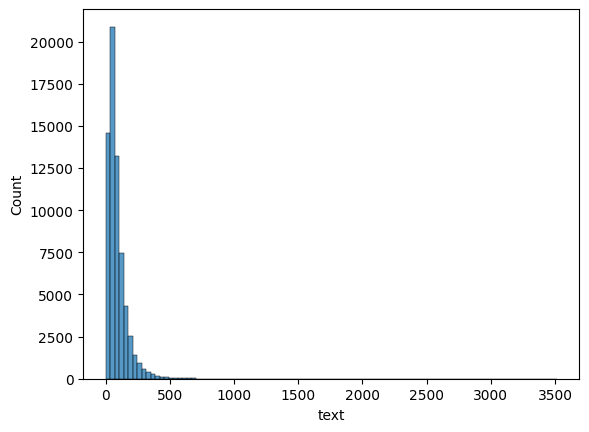

In [18]:
# 데이터셋에서 공백기준 단어의 수 확인
print(clothing_shoes_img['text'].apply(lambda row : len(row.split(' '))).describe().astype(int))

sns.histplot(clothing_shoes_img['text'].apply(lambda row : len(row.split(' '))), bins=100)

count    23801
mean       120
std        113
min          1
25%         49
50%         90
75%        155
max       2167
Name: text, dtype: int64


<Axes: xlabel='text', ylabel='Count'>

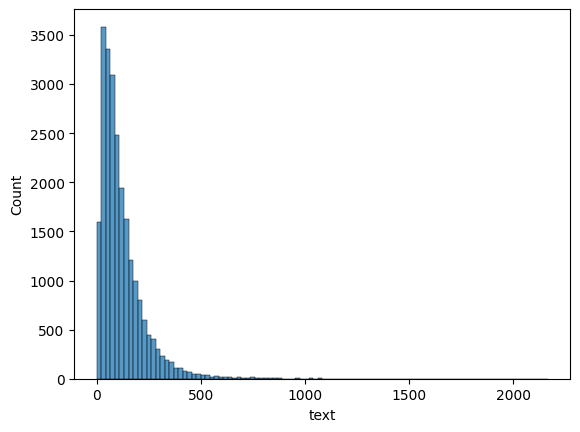

In [19]:
# 데이터셋에서 공백기준 단어의 수 확인
print(cell_phone_img['text'].apply(lambda row : len(row.split(' '))).describe().astype(int))

sns.histplot(cell_phone_img['text'].apply(lambda row : len(row.split(' '))), bins=100)

In [21]:
cell_phone_img['text'][0]

"Nice privacy shield. Good color, fits well, etc.<br /><br />HOWEVER, 1 of the 2 shields came scratched (see pic). It also didn't come with the cleaning cloth that the instructions reference to clean the screen before application. Sloppy execution for  the price IMO."

In [23]:
cell_phone_img_2 = pd.read_pickle('/content/drive/MyDrive/Dataset/Amazon_Dataset/Preprocessed/Cell_Phone_v3.pkl')
print(cell_phone_img_2.shape)
cell_phone_img_2.head()

(23698, 17)


,user_id,asin,parent_asin,text,rating,title_y,small_image_url,medium_image_url,large_image_url,roberta_emb,VGG16_emb,user_bert_emb,item_bert_emb,user_roberta_emb,item_roberta_emb,bert_emb,ViT_emb_768
0,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,B0BJKYJR3L,B0BJKYJR3L,"Nice privacy shield. Good color, fits well, et...",3,Jephuwneh 2 Pack Gradient Tempered Glass for i...,https://m.media-amazon.com/images/I/515oPLx13k...,https://m.media-amazon.com/images/I/515oPLx13k...,https://m.media-amazon.com/images/I/515oPLx13k...,"[-0.0753104165, 0.1205661818, -0.0582872108, -...","[21.9560680389, 19.9599552155, 0.0, 12.1845550...","[-0.50728655, -0.22111754, 0.44898894, -0.2970...","[-0.3555999, -0.19625245, 0.338061, -0.1889423...","[-0.05482221, 0.11866534, -0.037660137, -0.100...","[-0.05482221, 0.11866534, -0.037660137, -0.100...","[-0.4987579882, 0.0930124968, 0.5161928535, -0...","[0.29988617, -0.045542944, -0.8000981, 0.59209..."
1,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,B0BHTZQHQW,B0BHTZQHQW,"This thing is great. It's not too big, has a d...",5,"NEOCOR Magnetic Wireless Power Bank, 10,000mAh...",https://m.media-amazon.com/images/I/71K8BDxzsA...,https://m.media-amazon.com/images/I/71K8BDxzsA...,https://m.media-amazon.com/images/I/71K8BDxzsA...,"[-0.1076164767, 0.15895271300000002, -0.038697...","[21.0625953674, 20.1747741699, 25.1910858154, ...","[-0.50728655, -0.22111754, 0.44898894, -0.2970...","[-0.5915019, -0.69345254, 0.21792011, -0.13003...","[-0.05482221, 0.11866534, -0.037660137, -0.100...","[-0.07991053, 0.16881612, -0.014415792, -0.127...","[-0.31485173110000003, -0.4254012406, 0.202500...","[0.13607217, -0.6493865, -0.67186373, 0.232441..."
2,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,B0B9N4VRB9,B0BHSSCXB2,This is a much better way to mount my iPhone (...,5,Lamicall Gooseneck Phone Holder Bed - [Newest ...,https://m.media-amazon.com/images/I/71b+Sx-Jq7...,https://m.media-amazon.com/images/I/71b+Sx-Jq7...,https://m.media-amazon.com/images/I/71b+Sx-Jq7...,"[-0.098338306, 0.1566942036, -0.0378348567, -0...","[14.8097057343, 32.5932540894, 0.1909603626000...","[-0.50728655, -0.22111754, 0.44898894, -0.2970...","[-0.11259819, -0.25781307, 0.46874186, -0.3961...","[-0.05482221, 0.11866534, -0.037660137, -0.100...","[-0.085501574, 0.112952866, -0.022212008, -0.0...","[-0.1026419848, -0.13615188, 0.3662686348, -0....","[0.616384, 0.38489878, -0.8299023, 0.17923264,..."
3,AHUPTBY3F3UN2S5H7K5JLP6MAV5Q,B0B93H178F,B0B93H178F,"This is a fantastic charger, especially if you...",5,"Shargeek USB C Charger 140W Wall Charger, Mult...",https://m.media-amazon.com/images/I/61R6UXrAKT...,https://m.media-amazon.com/images/I/61R6UXrAKT...,https://m.media-amazon.com/images/I/61R6UXrAKT...,"[-0.0699621961, 0.1709383726, -0.0337884836, -...","[0.0, 23.3746795654, 9.155254364, 0.0, 0.0, 5....","[-0.50728655, -0.22111754, 0.44898894, -0.2970...","[-0.63115484, -0.17968105, 0.4211614, -0.10539...","[-0.05482221, 0.11866534, -0.037660137, -0.100...","[-0.05314668, 0.1396852, -0.016387641, -0.1113...","[-0.43984735010000003, -0.38499537110000004, 0...","[-0.16200905, -0.38682806, -0.49967474, 0.6539..."
4,AFERCDY2EFJKT7QUQ75GISNHTFOQ,B0BPXZWCBG,B0BPY47SY6,There never seems to be enough charging cords ...,4,"Charging Station for Multiple Devices,60W 12A ...",https://m.media-amazon.com/images/I/51fqzioGKe...,https://m.media-amazon.com/images/I/51fqzioGKe...,https://m.media-amazon.com/images/I/51fqzioGKe...,"[-0.09403285380000001, 0.16169938450000002, -0...","[24.7299823761, 20.3585853577, 0.0, 24.0320549...","[-0.30125153, -0.10725977, 0.31016856, -0.1977...","[-0.442251, -0.18747163, 0.23647779, -0.066458...","[-0.08094199, 0.124280974, -0.008204151, -0.07...","[-0.08094199, 0.124280974, -0.008204151, -0.07...","[-0.3146147728, -0.0535337627, 0.0628833473, -...","[-0.65507317, 0.21880366, -0.63748753, 0.00862..."


count     23698
mean       5310
std       13218
min         111
25%        1405
50%        2805
75%        5789
max      252356
Name: text, dtype: int64


<Axes: xlabel='text', ylabel='Count'>

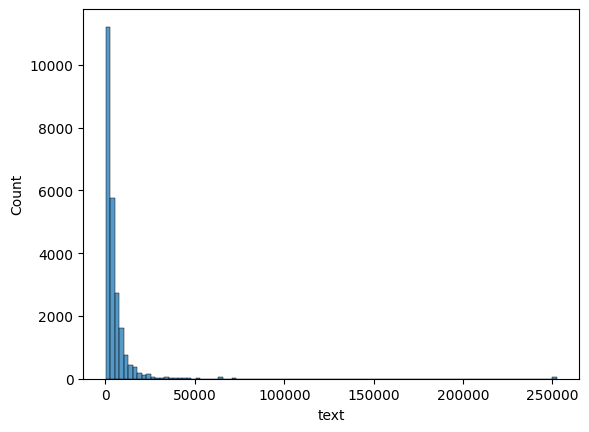

In [24]:
# 데이터셋에서 공백기준 단어의 수 확인
print(cell_phone_img_2['text'].apply(lambda row : len(row.split(' '))).describe().astype(int))

sns.histplot(cell_phone_img_2['text'].apply(lambda row : len(row.split(' '))), bins=100)